In [1]:
import cv2
import numpy as np
from pathlib import Path
from PIL import Image, UnidentifiedImageError

# Initial quality-checking criteria.
# These are starting values and must be validated on sample images.

MIN_WIDTH = 256
MIN_HEIGHT = 256

# Blur threshold using variance of the Laplacian.
MIN_BLUR_SCORE = 40.0

# Minimum fraction of pixels that should not be near-black.
MIN_NON_DARK_RATIO = 0.10

# Reject severely underexposed or overexposed images.
MIN_MEAN_BRIGHTNESS = 20.0
MAX_MEAN_BRIGHTNESS = 245.0

SUPPORTED_FORMATS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}

print("Image quality checker initialized.")
print("OpenCV version:", cv2.__version__)
print("Minimum dimensions:", MIN_WIDTH, "x", MIN_HEIGHT)
print("Initial blur threshold:", MIN_BLUR_SCORE)

Image quality checker initialized.
OpenCV version: 4.14.0
Minimum dimensions: 256 x 256
Initial blur threshold: 40.0


In [2]:
def check_image_quality(image_path):
    """
    Check whether an image is suitable to enter the fundus preprocessing
    pipeline. Returns PASS/FAIL, measured metrics, and reasons.
    """

    image_path = Path(image_path)
    result = {
        "image": image_path.name,
        "status": "FAIL",
        "reasons": [],
        "width": None,
        "height": None,
        "blur_score": None,
        "mean_brightness": None,
        "contrast_std": None,
        "non_dark_ratio": None,
        "retinal_field_ratio": None,
    }

    # 1. File and format validation
    if not image_path.is_file():
        result["reasons"].append("File does not exist.")
        return result

    if image_path.suffix.lower() not in SUPPORTED_FORMATS:
        result["reasons"].append("Unsupported file format.")
        return result

    try:
        with Image.open(image_path) as img:
            img.verify()

        image_bgr = cv2.imread(str(image_path), cv2.IMREAD_COLOR)

    except (UnidentifiedImageError, OSError, ValueError):
        result["reasons"].append("File is corrupted or unreadable.")
        return result

    if image_bgr is None:
        result["reasons"].append("Could not decode image.")
        return result

    height, width = image_bgr.shape[:2]
    result["width"] = width
    result["height"] = height

    # 2. Minimum dimensions
    if width < MIN_WIDTH or height < MIN_HEIGHT:
        result["reasons"].append(
            f"Image resolution too low: {width}x{height}."
        )

    # 3. Basic image metrics
    gray = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2GRAY)

    blur_score = float(cv2.Laplacian(gray, cv2.CV_64F).var())
    mean_brightness = float(gray.mean())
    contrast_std = float(gray.std())

    # Estimate whether pixels contain visible content rather than
    # an almost entirely black frame.
    non_dark_ratio = float(np.mean(gray > 10))

    # Estimate the visible circular retinal field using non-dark pixels.
    # This is a heuristic, not a fundus-image authenticity classifier.
    retinal_field_ratio = float(np.mean(gray > 15))

    result.update({
        "blur_score": blur_score,
        "mean_brightness": mean_brightness,
        "contrast_std": contrast_std,
        "non_dark_ratio": non_dark_ratio,
        "retinal_field_ratio": retinal_field_ratio,
    })

    # 4. Blur check
    if blur_score < MIN_BLUR_SCORE:
        result["reasons"].append(
            f"Image may be too blurry (score={blur_score:.1f})."
        )

    # 5. Brightness checks
    if mean_brightness < MIN_MEAN_BRIGHTNESS:
        result["reasons"].append("Image is severely underexposed.")

    if mean_brightness > MAX_MEAN_BRIGHTNESS:
        result["reasons"].append("Image is severely overexposed.")

    # 6. Content and contrast checks
    if non_dark_ratio < MIN_NON_DARK_RATIO:
        result["reasons"].append(
            "Image contains too little visible content."
        )

    if contrast_std < 8.0:
        result["reasons"].append(
            "Image contrast is extremely low."
        )

    # 7. Final decision
    result["status"] = "PASS" if not result["reasons"] else "FAIL"

    if result["status"] == "FAIL":
        result["reasons"] = list(dict.fromkeys(result["reasons"]))

    return result


print("Image quality checker function defined.")

Image quality checker function defined.


In [3]:
from pathlib import Path

# Original, unprocessed APTOS images
APTOS_ORIGINAL_DIR = Path(
    "/kaggle/input/datasets/mariaherrerot/aptos2019/train_images/train_images"
)

# Original, unprocessed IDRiD images
IDRID_ORIGINAL_DIR = Path(
    "/kaggle/input/datasets/mariaherrerot/idrid-dataset/Imagenes/Imagenes"
)

for name, folder in {
    "APTOS original images": APTOS_ORIGINAL_DIR,
    "IDRiD original images": IDRID_ORIGINAL_DIR,
}.items():
    print(f"\n{name}")
    print("Directory exists:", folder.exists())

    if folder.exists():
        images = [
            p for p in folder.iterdir()
            if p.is_file()
            and p.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}
        ]
        print("Image count:", len(images))
        print("Sample filenames:", [p.name for p in images[:5]])


APTOS original images
Directory exists: True
Image count: 2930
Sample filenames: ['6dcde47060f9.png', 'b49b2fac2514.png', 'af6166d57f13.png', '8d13c46e7d75.png', 'c3b15bf9b4bc.png']

IDRiD original images
Directory exists: True
Image count: 455
Sample filenames: ['IDRiD_179.jpg', 'IDRiD_193.jpg', 'IDRiD_316.jpg', 'IDRiD_407.jpg', 'IDRiD_335.jpg']


In [4]:
from pathlib import Path
import pandas as pd

APTOS_ORIGINAL_DIR = Path(
    "/kaggle/input/datasets/mariaherrerot/aptos2019/"
    "train_images/train_images"
)

IDRID_ORIGINAL_DIR = Path(
    "/kaggle/input/datasets/mariaherrerot/idrid-dataset/"
    "Imagenes/Imagenes"
)

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}

def get_image_paths(folder, limit=10):
    paths = sorted(
        p for p in folder.rglob("*")
        if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
    )
    return paths[:limit]

# Select 10 original images from each dataset
aptos_original_images = get_image_paths(APTOS_ORIGINAL_DIR, limit=10)
idrid_original_images = get_image_paths(IDRID_ORIGINAL_DIR, limit=10)

print("Original APTOS images selected:", len(aptos_original_images))
print("Original IDRiD images selected:", len(idrid_original_images))

# Run the quality checker
test_records = []

for dataset_name, paths in [
    ("APTOS", aptos_original_images),
    ("IDRiD", idrid_original_images)
]:
    for path in paths:
        result = check_image_quality(path)
        result["dataset"] = dataset_name
        test_records.append(result)

quality_test_df = pd.DataFrame(test_records)

display(
    quality_test_df[
        [
            "dataset", "image", "status",
            "width", "height", "blur_score",
            "mean_brightness", "contrast_std",
            "non_dark_ratio", "reasons"
        ]
    ]
)

print("\nPass/fail summary:")
display(
    quality_test_df.groupby(["dataset", "status"])
    .size()
    .unstack(fill_value=0)
)

Original APTOS images selected: 10
Original IDRiD images selected: 10


,dataset,image,status,width,height,blur_score,mean_brightness,contrast_std,non_dark_ratio,reasons
0,APTOS,1ae8c165fd53.png,FAIL,3216,2136,4.018016,69.354977,40.949887,0.745606,[Image may be too blurry (score=4.0).]
1,APTOS,1b329a127307.png,FAIL,2588,1958,14.160044,62.553056,34.875530,0.914658,[Image may be too blurry (score=14.2).]
2,APTOS,1b32e1d775ea.png,FAIL,1504,1000,30.042062,58.852342,35.920251,0.735124,[Image may be too blurry (score=30.0).]
3,APTOS,1b3647865779.png,FAIL,819,614,25.334857,37.877102,41.850182,0.475558,[Image may be too blurry (score=25.3).]
4,APTOS,1b398c0494d1.png,FAIL,1050,1050,38.474747,70.792219,38.147400,0.789954,[Image may be too blurry (score=38.5).]
5,APTOS,1b4625877527.png,FAIL,1504,1000,33.921119,69.100773,44.290250,0.735518,[Image may be too blurry (score=33.9).]
6,APTOS,1b495ac025b7.png,FAIL,2416,1736,11.721863,56.416056,28.264211,0.833265,[Image may be too blurry (score=11.7).]
7,APTOS,1b862fb6f65d.png,PASS,1050,1050,47.446535,70.049095,39.617205,0.790246,[]
8,APTOS,1b8701231c8f.png,FAIL,819,614,9.412302,38.685505,23.191062,0.797183,[Image may be too blurry (score=9.4).]
9,APTOS,1b8ad0afe9fb.png,FAIL,2588,1958,15.820906,90.460194,40.379356,0.907439,[Image may be too blurry (score=15.8).]



Pass/fail summary:


status,FAIL,PASS
dataset,,
APTOS,9,1
IDRiD,10,0


In [5]:
def calculate_standardized_blur(image_path, size=(512, 512)):
    image = cv2.imread(str(image_path))

    if image is None:
        return None

    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    gray = cv2.resize(gray, size, interpolation=cv2.INTER_AREA)

    # Ignore very dark pixels when estimating blur
    mask = gray > 15

    if mask.sum() < 100:
        return 0.0

    # Calculate Laplacian response on the standardized image
    laplacian = cv2.Laplacian(gray, cv2.CV_64F)

    return float(laplacian[mask].var())


blur_comparison = []

for dataset_name, paths in [
    ("APTOS", aptos_original_images),
    ("IDRiD", idrid_original_images)
]:
    for path in paths:
        blur_comparison.append({
            "dataset": dataset_name,
            "image": path.name,
            "original_blur": check_image_quality(path)["blur_score"],
            "standardized_blur": calculate_standardized_blur(path)
        })

blur_comparison_df = pd.DataFrame(blur_comparison)

display(blur_comparison_df.round(2))

print("\nStandardized blur score distribution:")
display(
    blur_comparison_df.groupby("dataset")["standardized_blur"]
    .describe()
    .round(2)
)

,dataset,image,original_blur,standardized_blur
0,APTOS,1ae8c165fd53.png,4.02,35.51
1,APTOS,1b329a127307.png,14.16,23.71
2,APTOS,1b32e1d775ea.png,30.04,30.20
3,APTOS,1b3647865779.png,25.33,40.11
4,APTOS,1b398c0494d1.png,38.47,55.93
5,APTOS,1b4625877527.png,33.92,58.81
6,APTOS,1b495ac025b7.png,11.72,31.09
7,APTOS,1b862fb6f65d.png,47.45,71.27
8,APTOS,1b8701231c8f.png,9.41,9.82
9,APTOS,1b8ad0afe9fb.png,15.82,10.77



Standardized blur score distribution:


,count,mean,std,min,25%,50%,75%,max
dataset,,,,,,,,
APTOS,10.0,36.72,20.29,9.82,25.33,33.30,51.97,71.27
IDRiD,10.0,41.92,16.20,13.62,36.42,41.23,50.32,69.58


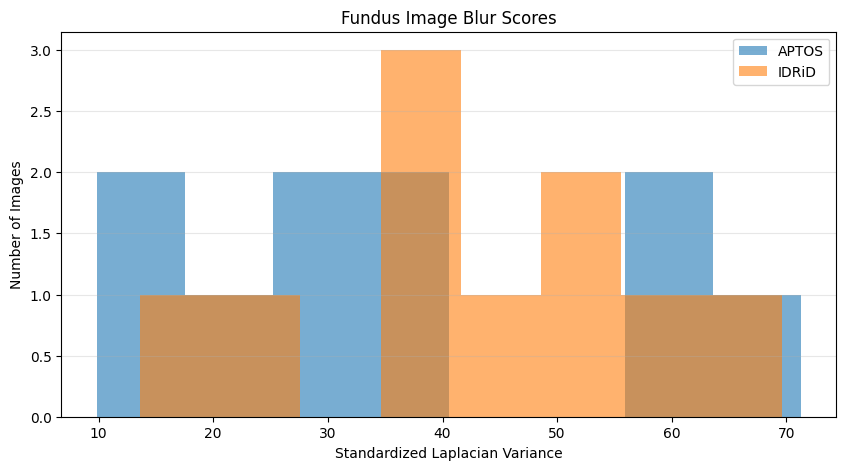

In [6]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

for dataset_name in ["APTOS", "IDRiD"]:
    scores = blur_comparison_df.loc[
        blur_comparison_df["dataset"] == dataset_name,
        "standardized_blur"
    ]
    plt.hist(scores, bins=8, alpha=0.6, label=dataset_name)

plt.xlabel("Standardized Laplacian Variance")
plt.ylabel("Number of Images")
plt.title("Fundus Image Blur Scores")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.show()

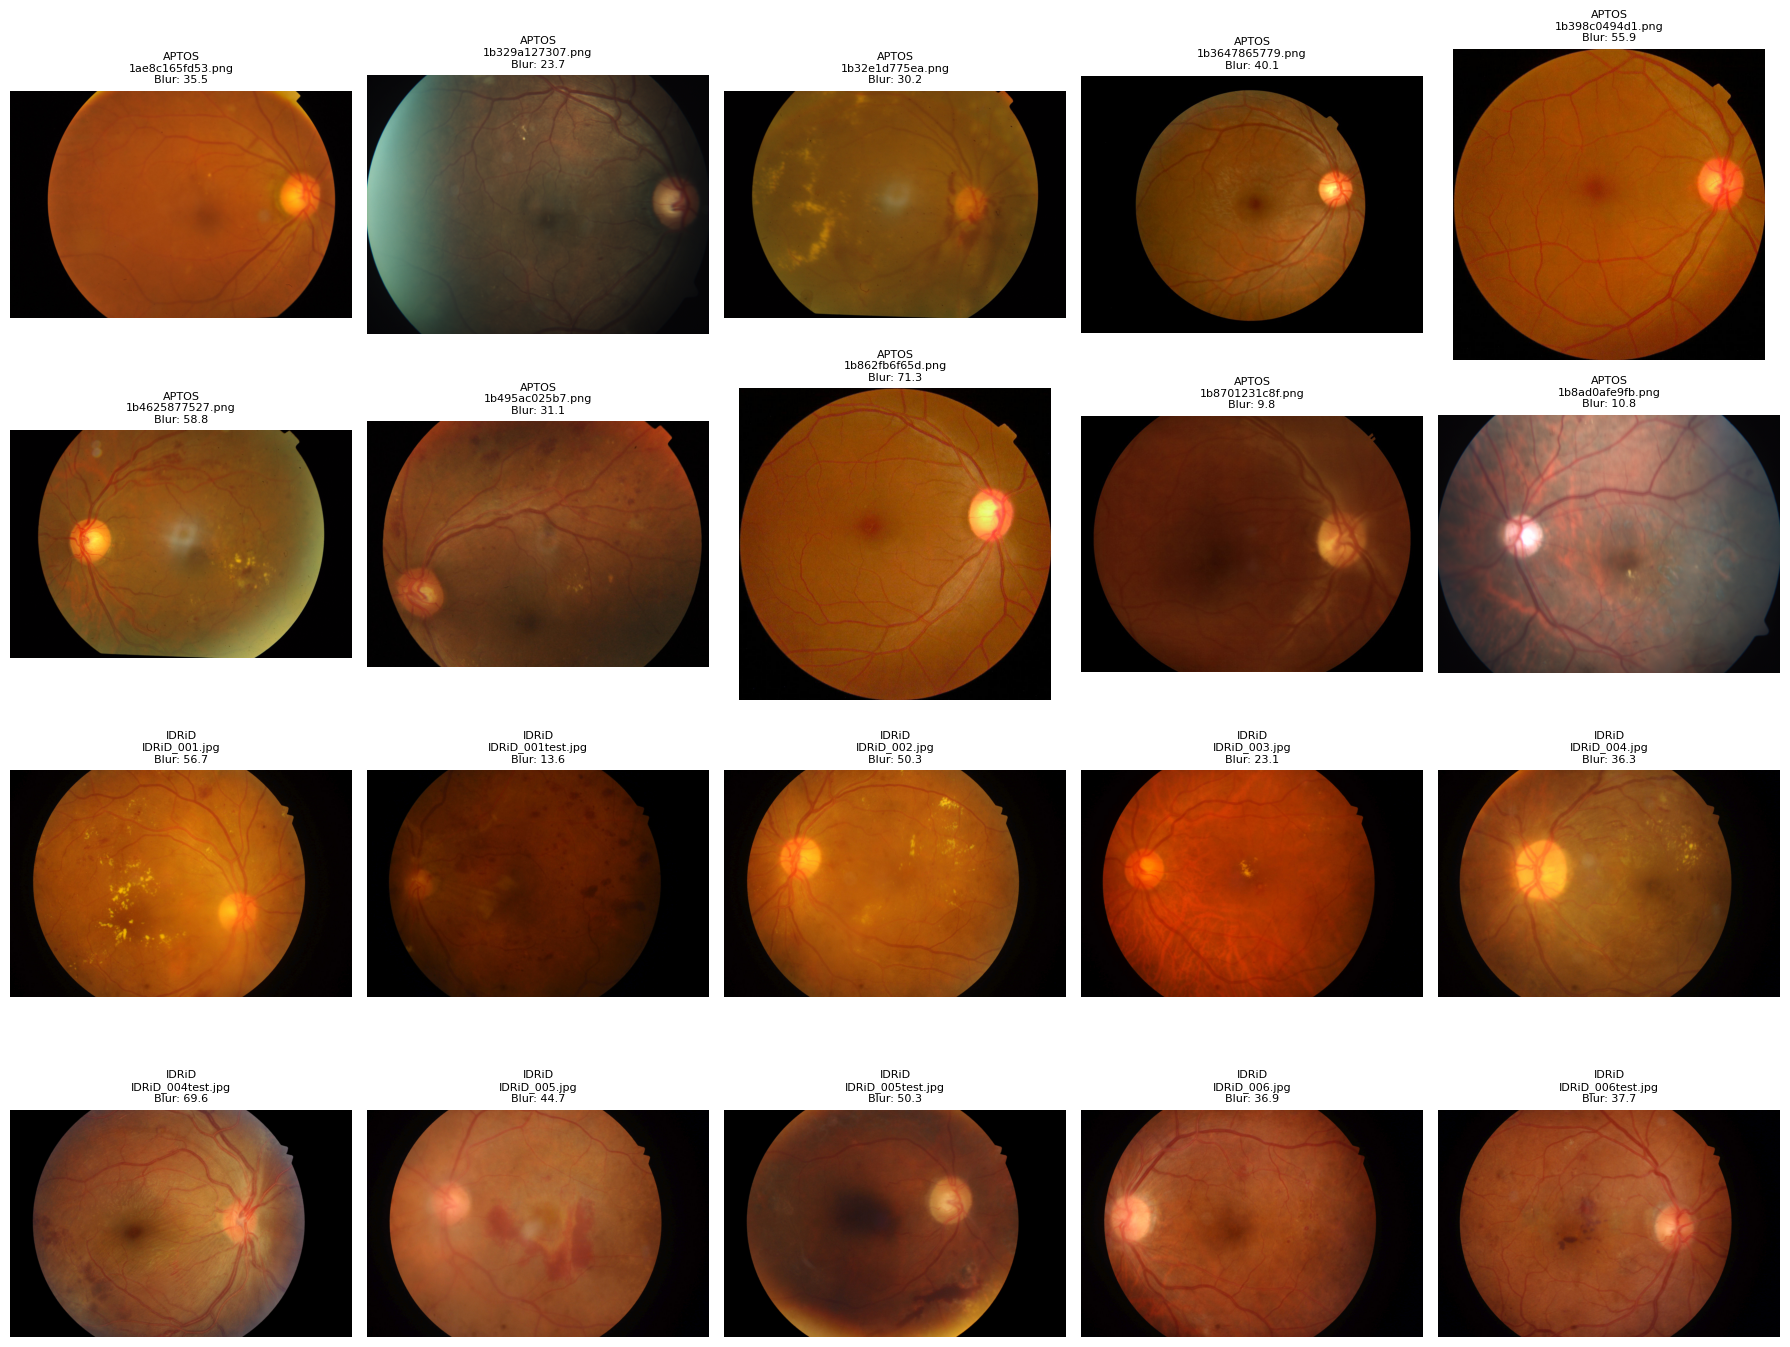

In [7]:
import matplotlib.pyplot as plt
import cv2

fig, axes = plt.subplots(4, 5, figsize=(18, 14))
axes = axes.flatten()

for i, row in blur_comparison_df.iterrows():
    dataset_name = row["dataset"]

    image_path = (
        next(p for p in aptos_original_images if p.name == row["image"])
        if dataset_name == "APTOS"
        else next(p for p in idrid_original_images if p.name == row["image"])
    )

    image = cv2.imread(str(image_path))
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    axes[i].imshow(image)
    axes[i].set_title(
        f"{dataset_name}\n{row['image']}\nBlur: {row['standardized_blur']:.1f}",
        fontsize=8
    )
    axes[i].axis("off")

plt.tight_layout()
plt.show()

In [8]:
def check_image_quality(image_path):
    image_path = Path(image_path)
    reasons = []

    if not image_path.exists():
        return {"image": image_path.name, "status": "FAIL",
                "reasons": ["File not found"]}

    if image_path.suffix.lower() not in SUPPORTED_EXTENSIONS:
        return {"image": image_path.name, "status": "FAIL",
                "reasons": ["Unsupported file extension"]}

    try:
        with Image.open(image_path) as img:
            img.verify()

        image = cv2.imread(str(image_path))
        if image is None:
            raise ValueError("Unable to decode image")

    except Exception:
        return {"image": image_path.name, "status": "FAIL",
                "reasons": ["Invalid or unreadable image"]}

    height, width = image.shape[:2]

    if width < MIN_WIDTH or height < MIN_HEIGHT:
        reasons.append("Resolution too low")

    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    standardized_gray = cv2.resize(
        gray, (512, 512), interpolation=cv2.INTER_AREA
    )

    # Estimate blur within the brighter image area.
    mask = standardized_gray > 15

    if mask.sum() < 100:
        blur_score = 0.0
    else:
        laplacian = cv2.Laplacian(
            standardized_gray, cv2.CV_64F
        )
        blur_score = float(laplacian[mask].var())

    mean_brightness = float(gray.mean())
    contrast = float(gray.std())
    non_dark_ratio = float((gray > 10).mean())

    if blur_score < 15:
        reasons.append("Possible blur or poor image detail")

    if mean_brightness < MIN_MEAN_BRIGHTNESS:
        reasons.append("Image too dark")
    elif mean_brightness > MAX_MEAN_BRIGHTNESS:
        reasons.append("Image too bright")

    if non_dark_ratio < MIN_NON_DARK_RATIO:
        reasons.append("Insufficient visible image area")

    if contrast < 8:
        reasons.append("Very low contrast")

    # Basic circular/elliptical fundus appearance heuristic.
    # This is not a trained fundus classifier.
    h, w = gray.shape
    center_region = gray[int(h * 0.1):int(h * 0.9),
                         int(w * 0.1):int(w * 0.9)]
    center_brightness = float(center_region.mean())

    if center_brightness < 10:
        reasons.append("No clearly visible central retinal field")

    return {
        "image": image_path.name,
        "width": width,
        "height": height,
        "blur_score": round(blur_score, 2),
        "mean_brightness": round(mean_brightness, 2),
        "contrast": round(contrast, 2),
        "status": "PASS" if not reasons else "FAIL",
        "reasons": reasons if reasons else ["No heuristic issues detected"]
    }

In [9]:
SUPPORTED_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}

print("Supported extensions:", sorted(SUPPORTED_EXTENSIONS))
print("APTOS sample images:", len(aptos_original_images))
print("IDRiD sample images:", len(idrid_original_images))

Supported extensions: ['.bmp', '.jpeg', '.jpg', '.png', '.tif', '.tiff']
APTOS sample images: 10
IDRiD sample images: 10


In [10]:
import pandas as pd

quality_results = []

for dataset_name, image_paths in [
    ("APTOS", aptos_original_images),
    ("IDRiD", idrid_original_images)
]:
    for image_path in image_paths:
        result = check_image_quality(image_path)
        result["dataset"] = dataset_name
        quality_results.append(result)

quality_results_df = pd.DataFrame(quality_results)

display(
    quality_results_df[
        ["dataset", "image", "blur_score", "mean_brightness",
         "contrast", "status", "reasons"]
    ]
)

print("\nSummary by dataset:")
display(
    quality_results_df.groupby(["dataset", "status"])
    .size()
    .unstack(fill_value=0)
)

print("\nFailure reasons:")
for dataset_name in ["APTOS", "IDRiD"]:
    print(f"\n{dataset_name}")
    failures = quality_results_df[
        (quality_results_df["dataset"] == dataset_name) &
        (quality_results_df["status"] == "FAIL")
    ]
    if failures.empty:
        print("No failures")
    else:
        for _, row in failures.iterrows():
            print(f"{row['image']}: {', '.join(row['reasons'])}")

,dataset,image,blur_score,mean_brightness,contrast,status,reasons
0,APTOS,1ae8c165fd53.png,35.51,69.35,40.95,PASS,[No heuristic issues detected]
1,APTOS,1b329a127307.png,23.71,62.55,34.88,PASS,[No heuristic issues detected]
2,APTOS,1b32e1d775ea.png,30.20,58.85,35.92,PASS,[No heuristic issues detected]
3,APTOS,1b3647865779.png,40.11,37.88,41.85,PASS,[No heuristic issues detected]
4,APTOS,1b398c0494d1.png,55.93,70.79,38.15,PASS,[No heuristic issues detected]
5,APTOS,1b4625877527.png,58.81,69.10,44.29,PASS,[No heuristic issues detected]
6,APTOS,1b495ac025b7.png,31.09,56.42,28.26,PASS,[No heuristic issues detected]
7,APTOS,1b862fb6f65d.png,71.27,70.05,39.62,PASS,[No heuristic issues detected]
8,APTOS,1b8701231c8f.png,9.82,38.69,23.19,FAIL,[Possible blur or poor image detail]
9,APTOS,1b8ad0afe9fb.png,10.77,90.46,40.38,FAIL,[Possible blur or poor image detail]



Summary by dataset:


status,FAIL,PASS
dataset,,
APTOS,2,8
IDRiD,1,9



Failure reasons:

APTOS
1b8701231c8f.png: Possible blur or poor image detail
1b8ad0afe9fb.png: Possible blur or poor image detail

IDRiD
IDRiD_001test.jpg: Possible blur or poor image detail


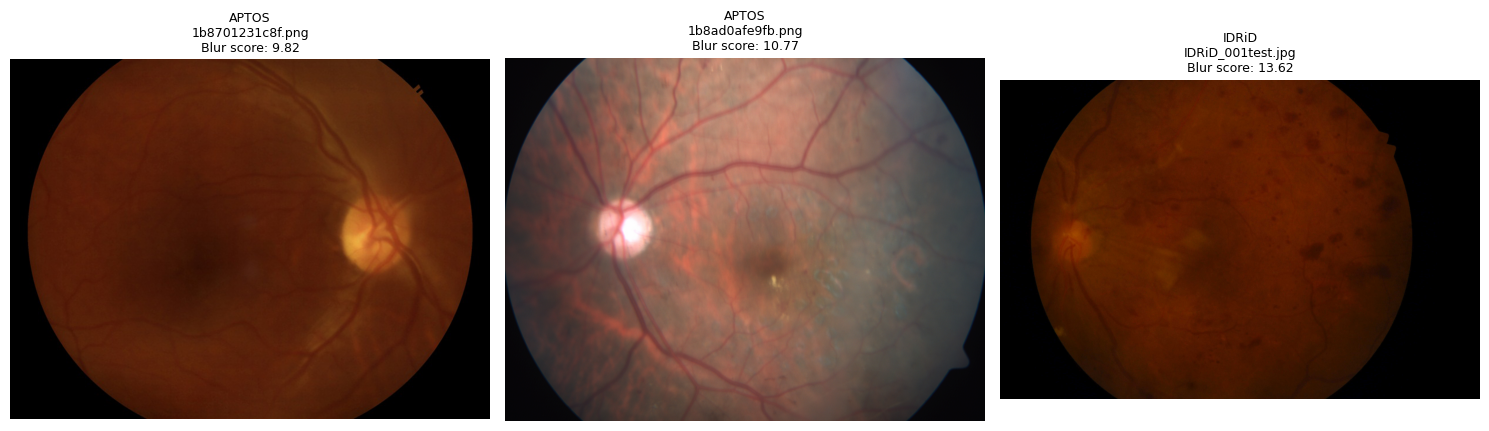

In [11]:
import matplotlib.pyplot as plt
import cv2

failed_images = quality_results_df[
    quality_results_df["status"] == "FAIL"
]

fig, axes = plt.subplots(
    1, max(len(failed_images), 1),
    figsize=(5 * max(len(failed_images), 1), 5)
)

if len(failed_images) == 1:
    axes = [axes]

for ax, (_, row) in zip(axes, failed_images.iterrows()):
    dataset_name = row["dataset"]

    image_path = (
        next(p for p in aptos_original_images if p.name == row["image"])
        if dataset_name == "APTOS"
        else next(p for p in idrid_original_images if p.name == row["image"])
    )

    image = cv2.imread(str(image_path))
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    ax.imshow(image)
    ax.set_title(
        f"{dataset_name}\n{row['image']}\n"
        f"Blur score: {row['blur_score']}",
        fontsize=9
    )
    ax.axis("off")

plt.tight_layout()
plt.show()

In [12]:
import pandas as pd
from pathlib import Path

# Collect every original APTOS image
aptos_all_images = get_image_paths(APTOS_ORIGINAL_DIR, limit=None)

print(f"Total APTOS images found: {len(aptos_all_images)}")

# Evaluate every image
aptos_quality_results = []

for i, image_path in enumerate(aptos_all_images, start=1):
    result = check_image_quality(image_path)
    result["dataset"] = "APTOS"
    aptos_quality_results.append(result)

    if i % 250 == 0 or i == len(aptos_all_images):
        print(f"Processed {i}/{len(aptos_all_images)} images")

# Create results DataFrame
aptos_quality_df = pd.DataFrame(aptos_quality_results)

# Overall summary
print("\nAPTOS Quality Evaluation Summary")
display(
    aptos_quality_df["status"]
    .value_counts()
    .rename_axis("Status")
    .to_frame("Image Count")
)

# Failure reasons
print("\nFailure reasons:")
failed_aptos = aptos_quality_df[
    aptos_quality_df["status"] == "FAIL"
]

if failed_aptos.empty:
    print("No images failed the current checks.")
else:
    for _, row in failed_aptos.iterrows():
        print(f"{row['image']}: {', '.join(row['reasons'])}")

# Save results for later analysis
output_path = Path("/kaggle/working/aptos_quality_evaluation.csv")
aptos_quality_df.to_csv(output_path, index=False)

print(f"\nResults saved to: {output_path}")

Total APTOS images found: 2930
Processed 250/2930 images
Processed 500/2930 images
Processed 750/2930 images
Processed 1000/2930 images
Processed 1250/2930 images
Processed 1500/2930 images
Processed 1750/2930 images
Processed 2000/2930 images
Processed 2250/2930 images
Processed 2500/2930 images
Processed 2750/2930 images
Processed 2930/2930 images

APTOS Quality Evaluation Summary


,Image Count
Status,
PASS,2633
FAIL,297



Failure reasons:
1b8701231c8f.png: Possible blur or poor image detail
1b8ad0afe9fb.png: Possible blur or poor image detail
1ca62b3e4fd3.png: Possible blur or poor image detail
1d11794057ff.png: Possible blur or poor image detail
1d29cb2f4296.png: Possible blur or poor image detail
1db18bdd43aa.png: Possible blur or poor image detail
1e036f2e7095.png: Possible blur or poor image detail
1fddd7c98fd2.png: Possible blur or poor image detail
21d18b022429.png: Possible blur or poor image detail
2209daf71aab.png: Possible blur or poor image detail
222d0ac042b4.png: Possible blur or poor image detail
237c078d00fc.png: Possible blur or poor image detail
24f3e70f0419.png: Possible blur or poor image detail
2682e6da9050.png: Possible blur or poor image detail
269b44e628eb.png: Possible blur or poor image detail
269f0792f11f.png: Possible blur or poor image detail
26d60db3bbfd.png: Possible blur or poor image detail
27f82ada84ac.png: Possible blur or poor image detail
286e9981dd9b.png: Possible b

In [13]:
from collections import Counter

failed_aptos = aptos_quality_df[
    aptos_quality_df["status"] == "FAIL"
]

reason_counts = Counter()

for reasons in failed_aptos["reasons"]:
    for reason in reasons:
        reason_counts[reason] += 1

reason_summary_df = pd.DataFrame(
    reason_counts.items(),
    columns=["Failure Reason", "Image Count"]
).sort_values("Image Count", ascending=False)

display(reason_summary_df)

print("Total failed images:", len(failed_aptos))
print(
    "Images failing blur check:",
    failed_aptos["reasons"].apply(
        lambda reasons: "Possible blur or poor image detail" in reasons
    ).sum()
)

,Failure Reason,Image Count
0,Possible blur or poor image detail,284
1,Image too dark,13


Total failed images: 297
Images failing blur check: 284


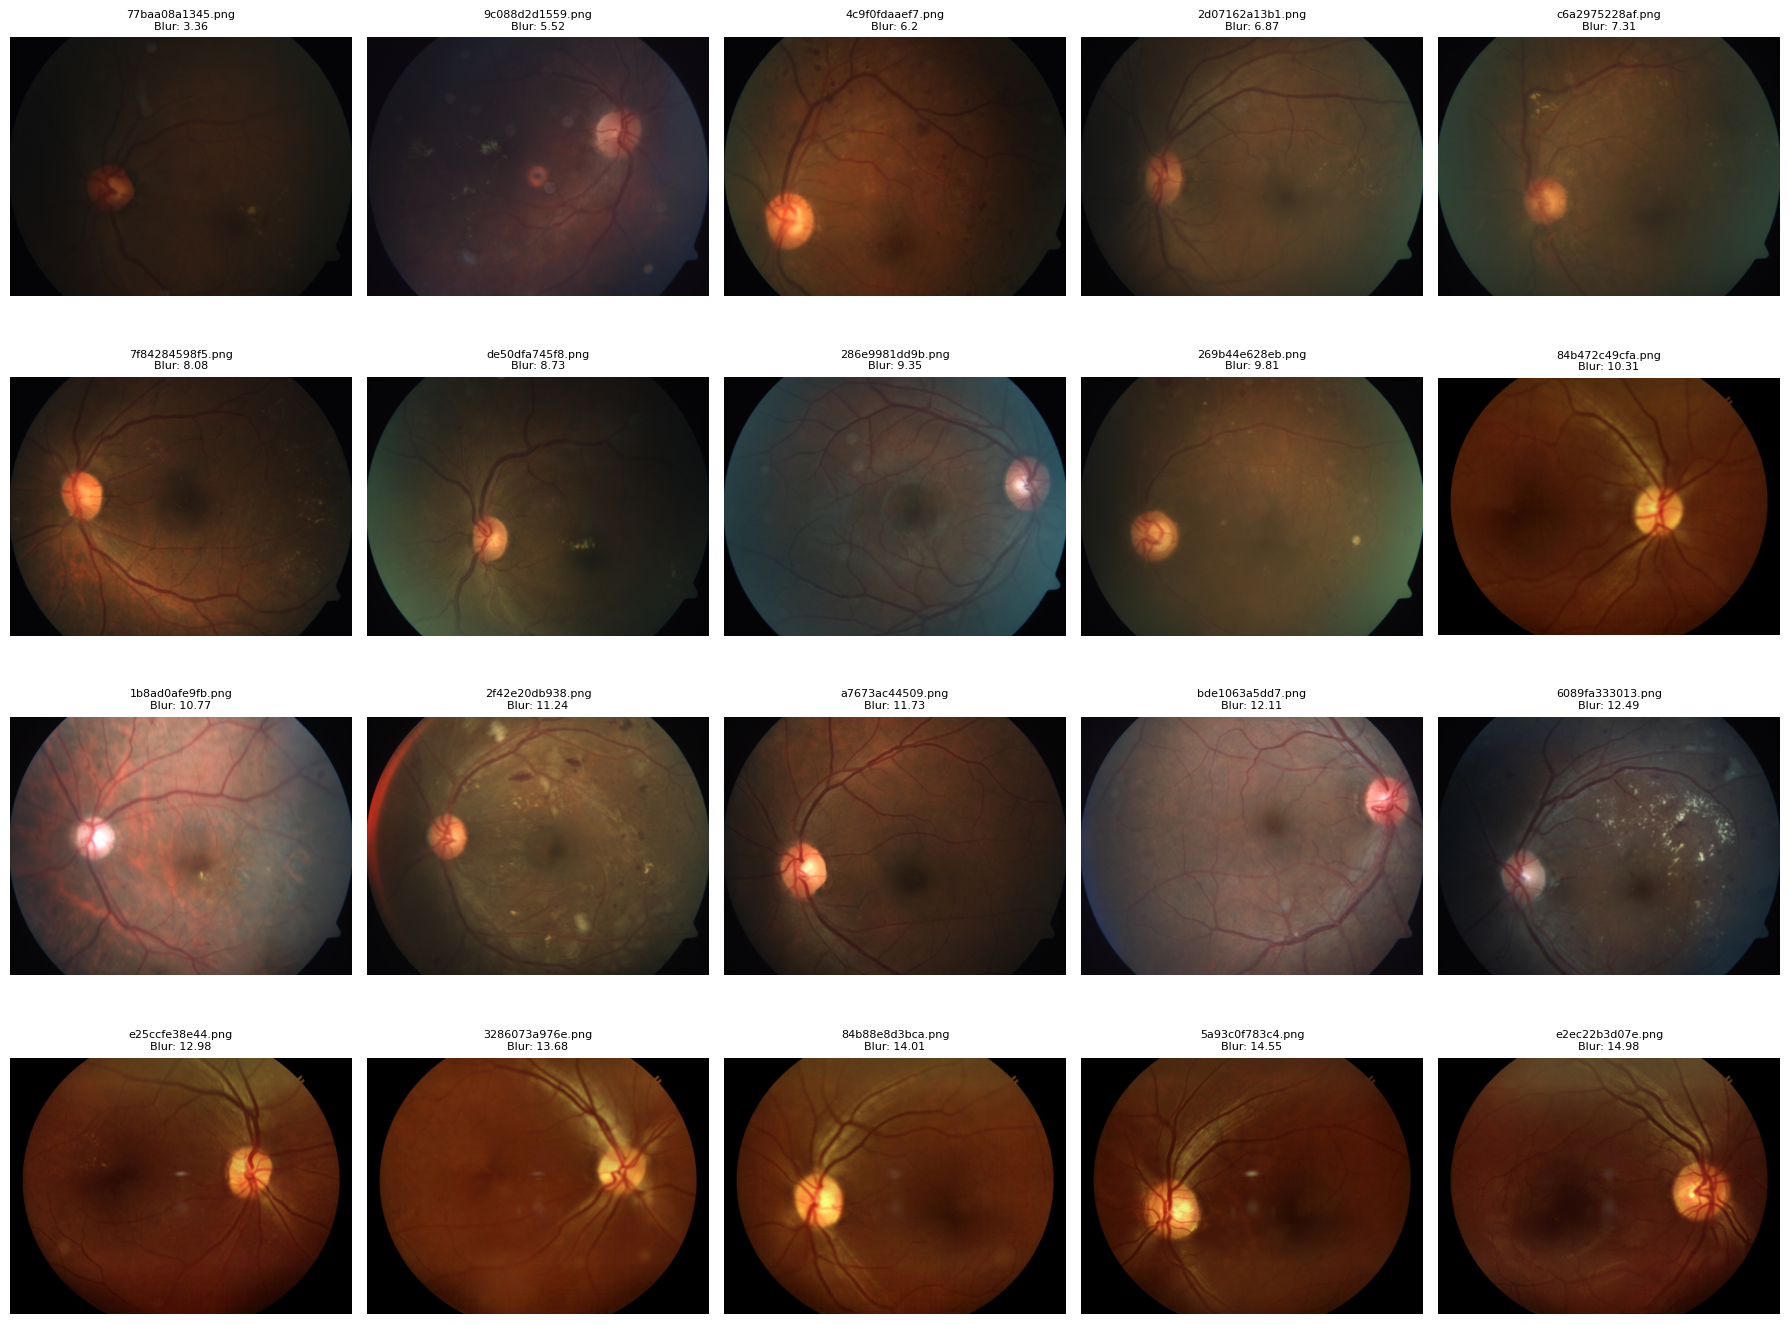

In [14]:
import matplotlib.pyplot as plt
import cv2
import numpy as np

blur_failures = failed_aptos[
    failed_aptos["reasons"].apply(
        lambda reasons: "Possible blur or poor image detail" in reasons
    )
].copy()

# Select 20 images spread across the blur-score range
blur_failures = blur_failures.sort_values("blur_score")

sample_indices = np.linspace(
    0, len(blur_failures) - 1,
    min(20, len(blur_failures)),
    dtype=int
)

review_images = blur_failures.iloc[sample_indices]

fig, axes = plt.subplots(4, 5, figsize=(18, 14))
axes = axes.flatten()

for ax, (_, row) in zip(axes, review_images.iterrows()):
    image_path = next(
        p for p in aptos_all_images
        if p.name == row["image"]
    )

    image = cv2.imread(str(image_path))
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    ax.imshow(image)
    ax.set_title(
        f"{row['image']}\nBlur: {row['blur_score']}",
        fontsize=8
    )
    ax.axis("off")

for ax in axes[len(review_images):]:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [15]:
from pathlib import Path
import pandas as pd

APTOS_LABEL_CSV = Path(
    "/kaggle/input/datasets/mariaherrerot/aptos2019/train_1.csv"
)

APTOS_ORIGINAL_DIR = Path(
    "/kaggle/input/datasets/mariaherrerot/aptos2019/train_images/train_images"
)

# Verify both paths
print("Label CSV exists:", APTOS_LABEL_CSV.exists())
print("Original image directory exists:", APTOS_ORIGINAL_DIR.exists())

# Load the ground-truth labels
labels_df = pd.read_csv(APTOS_LABEL_CSV)

print("\nLabel columns:", labels_df.columns.tolist())
print("Number of labeled images:", len(labels_df))
display(labels_df.head())

Label CSV exists: True
Original image directory exists: True

Label columns: ['id_code', 'diagnosis']
Number of labeled images: 2930


,id_code,diagnosis
0,1ae8c165fd53,2
1,1b329a127307,1
2,1b32e1d775ea,4
3,1b3647865779,0
4,1b398c0494d1,0


In [16]:
# Match failed images with APTOS ground-truth labels

labels_df["image_filename"] = labels_df["id_code"].astype(str) + ".png"

image_path_lookup = {
    path.name: str(path)
    for path in aptos_all_images
}

failed_aptos = aptos_quality_df[
    aptos_quality_df["status"] == "FAIL"
].copy()

failed_aptos["image_filename"] = failed_aptos["image"]

failed_aptos_csv = failed_aptos.merge(
    labels_df[["image_filename", "diagnosis"]],
    on="image_filename",
    how="left",
    validate="one_to_one"
)

failed_aptos_csv = failed_aptos_csv.rename(
    columns={"diagnosis": "true_grade"}
)

failed_aptos_csv["image_path"] = (
    failed_aptos_csv["image_filename"].map(image_path_lookup)
)

# Validate matches
print("Failed images:", len(failed_aptos_csv))
print("Missing labels:", failed_aptos_csv["true_grade"].isna().sum())
print("Missing image paths:", failed_aptos_csv["image_path"].isna().sum())

display(
    failed_aptos_csv[
        ["image_filename", "image_path", "true_grade",
         "blur_score", "reasons"]
    ].head(10)
)

output_csv = Path(
    "/kaggle/working/aptos_failed_quality_images_with_labels.csv"
)

failed_aptos_csv.to_csv(output_csv, index=False)
print("\nSaved CSV:", output_csv)

Failed images: 297
Missing labels: 0
Missing image paths: 0


,image_filename,image_path,true_grade,blur_score,reasons
0,1b8701231c8f.png,/kaggle/input/datasets/mariaherrerot/aptos2019...,0,9.82,[Possible blur or poor image detail]
1,1b8ad0afe9fb.png,/kaggle/input/datasets/mariaherrerot/aptos2019...,2,10.77,[Possible blur or poor image detail]
2,1ca62b3e4fd3.png,/kaggle/input/datasets/mariaherrerot/aptos2019...,0,13.69,[Possible blur or poor image detail]
3,1d11794057ff.png,/kaggle/input/datasets/mariaherrerot/aptos2019...,1,14.97,[Possible blur or poor image detail]
4,1d29cb2f4296.png,/kaggle/input/datasets/mariaherrerot/aptos2019...,0,14.20,[Possible blur or poor image detail]
5,1db18bdd43aa.png,/kaggle/input/datasets/mariaherrerot/aptos2019...,2,7.64,[Possible blur or poor image detail]
6,1e036f2e7095.png,/kaggle/input/datasets/mariaherrerot/aptos2019...,0,13.88,[Possible blur or poor image detail]
7,1fddd7c98fd2.png,/kaggle/input/datasets/mariaherrerot/aptos2019...,0,6.64,[Possible blur or poor image detail]
8,21d18b022429.png,/kaggle/input/datasets/mariaherrerot/aptos2019...,4,12.96,[Possible blur or poor image detail]
9,2209daf71aab.png,/kaggle/input/datasets/mariaherrerot/aptos2019...,0,6.83,[Possible blur or poor image detail]



Saved CSV: /kaggle/working/aptos_failed_quality_images_with_labels.csv


In [17]:
from pathlib import Path
import pandas as pd

# Load preprocessed labels
preprocessed_labels_df = pd.read_csv(PREPROCESSED_LABELS_CSV)

# Normalize image IDs to strings without file extensions
preprocessed_labels_df["id_code"] = (
    preprocessed_labels_df["id_code"].astype(str).str.replace(
        r"\.(png|jpg|jpeg)$", "", regex=True, case=False
    )
)

# Index available preprocessed images by filename stem
preprocessed_image_paths = [
    p for p in PREPROCESSED_DIR.rglob("*")
    if p.is_file() and p.suffix.lower() in {".png", ".jpg", ".jpeg"}
]

preprocessed_path_lookup = {
    p.stem: str(p) for p in preprocessed_image_paths
}

print("Preprocessed image files found:", len(preprocessed_image_paths))

# Original APTOS ground-truth labels
original_labels = labels_df[["id_code", "diagnosis"]].copy()
original_labels["id_code"] = original_labels["id_code"].astype(str)

# Failed quality-check images and their original labels
failed_ids = failed_aptos_csv.copy()
failed_ids["id_code"] = failed_ids["image_filename"].str.replace(
    r"\.(png|jpg|jpeg)$", "", regex=True, case=False
)

# Join original labels and preprocessed labels using image ID
matched_df = failed_ids.merge(
    original_labels.rename(columns={"diagnosis": "original_grade"}),
    on="id_code",
    how="left",
    validate="many_to_one"
)

matched_df = matched_df.merge(
    preprocessed_labels_df.rename(
        columns={"diagnosis": "preprocessed_grade"}
    ),
    on="id_code",
    how="left",
    validate="many_to_one"
)

matched_df["preprocessed_path"] = matched_df["id_code"].map(
    preprocessed_path_lookup
)

matched_df["label_match"] = (
    matched_df["original_grade"] == matched_df["preprocessed_grade"]
)

print("\nFailed images:", len(matched_df))
print("Matched preprocessed paths:", matched_df["preprocessed_path"].notna().sum())
print("Missing preprocessed paths:", matched_df["preprocessed_path"].isna().sum())
print("Missing original labels:", matched_df["original_grade"].isna().sum())
print("Missing preprocessed labels:", matched_df["preprocessed_grade"].isna().sum())
print("Original/preprocessed label mismatches:", (~matched_df["label_match"]).sum())

display(
    matched_df[
        ["id_code", "original_grade", "preprocessed_grade",
         "preprocessed_path", "label_match"]
    ].head(10)
)

NameError: name 'PREPROCESSED_LABELS_CSV' is not defined

In [ ]:
import numpy as np
import pandas as pd
import tensorflow as tf
from PIL import Image

# Load the finalized fine-tuned model
model = tf.keras.models.load_model(MODEL_PATH)

print("Model input shape:", model.input_shape)
print("Model output shape:", model.output_shape)

# Confirm expected five-class output
assert model.output_shape[-1] == 5, (
    "Expected a five-class DR model."
)

# Match model input dimensions
input_height = model.input_shape[1]
input_width = model.input_shape[2]

X = []

for image_path in matched_df["preprocessed_path"]:
    with Image.open(image_path) as img:
        img = img.convert("RGB").resize(
            (input_width, input_height)
        )
        X.append(np.asarray(img, dtype=np.float32))

X = np.stack(X)

print("Prediction input shape:", X.shape)
print("Input pixel range:", X.min(), "to", X.max())

# Predict in batches
probabilities = model.predict(X, batch_size=32, verbose=1)

predicted_grades = np.argmax(probabilities, axis=1)
confidence = np.max(probabilities, axis=1)

# Add predictions to the matched table
prediction_results_df = matched_df.copy()
prediction_results_df["predicted_grade"] = predicted_grades
prediction_results_df["confidence"] = confidence
prediction_results_df["correct"] = (
    prediction_results_df["predicted_grade"]
    == prediction_results_df["original_grade"]
)

# Convert five-class grades to binary categories
prediction_results_df["true_binary"] = np.where(
    prediction_results_df["original_grade"] <= 1,
    "Non-Referable",
    "Referable"
)

prediction_results_df["predicted_binary"] = np.where(
    prediction_results_df["predicted_grade"] <= 1,
    "Non-Referable",
    "Referable"
)

prediction_results_df["binary_correct"] = (
    prediction_results_df["true_binary"]
    == prediction_results_df["predicted_binary"]
)

display(
    prediction_results_df[
        ["id_code", "original_grade", "predicted_grade",
         "confidence", "correct", "true_binary",
         "predicted_binary", "binary_correct"]
    ].head(15)
)

In [ ]:
# Five-class evaluation (grades 0–4)
total_images = len(prediction_results_df)

correct_5class = int(prediction_results_df["correct"].sum())
incorrect_5class = total_images - correct_5class
accuracy_5class = correct_5class / total_images * 100

# Binary evaluation (Non-Referable vs Referable)
correct_binary = int(prediction_results_df["binary_correct"].sum())
incorrect_binary = total_images - correct_binary
accuracy_binary = correct_binary / total_images * 100

print("=" * 45)
print("EFFICIENTNETB0 — FAILED-QUALITY APTOS IMAGES")
print("=" * 45)

print(f"\nTotal images evaluated: {total_images}")

print("\nFive-Class Classification (Grades 0–4)")
print(f"Correct predictions   : {correct_5class}/{total_images}")
print(f"Incorrect predictions : {incorrect_5class}/{total_images}")
print(f"Accuracy              : {accuracy_5class:.2f}%")

print("\nBinary Classification")
print(f"Correct predictions   : {correct_binary}/{total_images}")
print(f"Incorrect predictions : {incorrect_binary}/{total_images}")
print(f"Accuracy              : {accuracy_binary:.2f}%")

print("=" * 45)

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image
import math

# Display the first 10 failed-quality images
n_images = min(10, len(prediction_results_df))
n_cols = 2
n_rows = math.ceil(n_images / n_cols)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(12, n_rows * 5))
axes = axes.flatten()

for i in range(n_images):
    row = prediction_results_df.iloc[i]

    image = Image.open(row["preprocessed_path"]).convert("RGB")

    axes[i].imshow(image)
    axes[i].set_title(
        f"Image: {row['id_code']}\n"
        f"True grade: {row['original_grade']} | "
        f"Predicted: {row['predicted_grade']}\n"
        f"Confidence: {row['confidence']:.2%} | "
        f"{'CORRECT' if row['correct'] else 'INCORRECT'}",
        fontsize=10
    )
    axes[i].axis("off")

for i in range(n_images, len(axes)):
    axes[i].axis("off")

plt.tight_layout()
plt.show()